# ProductPulse - Churn model

Fit logistic regression using cutoff-based features and a 90-day churn target. The feature query is in `sql/features/churn_model_features.sql`.

The dataset is simulated using churn outcomes, and population selection can use later information. This is a demonstration model rather than a prospective performance estimate.


**Data scope:** Usage histories and lifecycle dates are reconstructed or simulated using churn outcomes. See the [methodology and known issues](../docs/project_review.md) when interpreting results.

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, roc_auc_score, roc_curve,
                              confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

load_dotenv('../.env', override=True)
db_url = URL.create(
    'postgresql+psycopg2',
    username=os.getenv('PGUSER'),
    password=os.getenv('PGPASSWORD', ''),
    host=os.getenv('PGHOST', 'localhost'),
    port=int(os.getenv('PGPORT', '5432')),
    database=os.getenv('PGDATABASE'),
)
engine = create_engine(db_url)

with open('../sql/features/churn_model_features.sql') as f:
    df = pd.read_sql(text(f.read()), engine)

print(df.shape)
df.head()


(4880, 13)


,user_id,plan,acquisition_channel,country,tenure_days_at_cutoff,recency_days_at_cutoff,events_last_30d,events_last_90d,sessions_last_90d,distinct_features_used,payments_before_cutoff,revenue_before_cutoff,churned_after_cutoff
0,0002-ORFBO,Pro,Partner,United States,194,0,14,23,7,9,6,393.60,0
1,0003-MKNFE,Pro,Referral,Germany,206,4,13,46,14,10,7,419.30,0
2,0013-MHZWF,Pro,Organic Search,United States,206,0,17,50,13,9,7,485.80,0
3,0013-SMEOE,Enterprise,Referral,Canada,2090,8,12,36,10,10,69,7569.30,0
4,0014-BMAQU,Enterprise,Referral,United Kingdom,1843,11,19,43,13,10,61,5163.65,0


## Class balance

In [2]:
n_pos = df['churned_after_cutoff'].sum()
n = len(df)
print(f"{n} users at risk as of the cutoff; {n_pos} ({n_pos/n:.1%}) churned in the following 90 days")
print()
print("This is a heavily imbalanced target. A model that always predicts "
      "'won't churn' would already score", f"{1 - n_pos/n:.1%} accuracy", "-- useless, but a reminder "
      "that accuracy alone is the wrong metric to judge this model on. class_weight='balanced' and "
      "precision/recall/ROC-AUC are used instead of plain accuracy below.")


4880 users at risk as of the cutoff; 107 (2.2%) churned in the following 90 days

This is a heavily imbalanced target. A model that always predicts 'won't churn' would already score 97.8% accuracy -- useless, but a reminder that accuracy alone is the wrong metric to judge this model on. class_weight='balanced' and precision/recall/ROC-AUC are used instead of plain accuracy below.


## Check feature correlation

Inspect correlated engagement and billing features before selecting model inputs. Redundant predictors can make individual coefficients unstable.


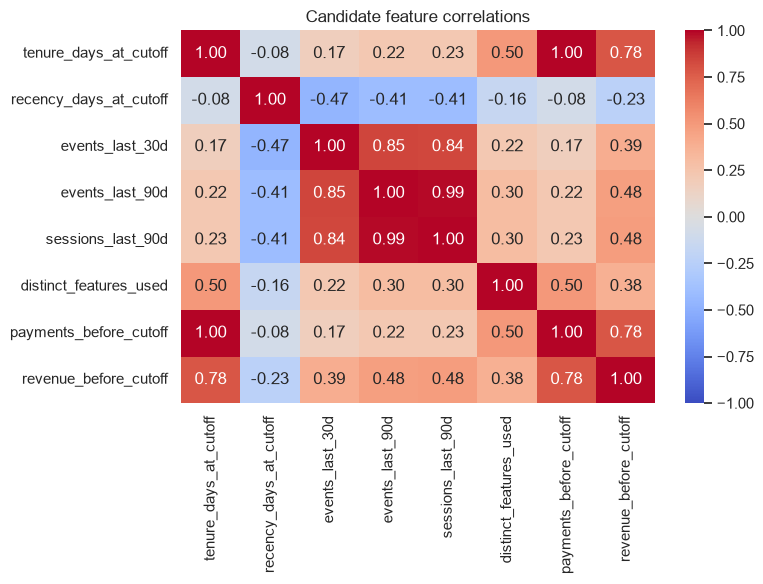

In [3]:
candidate_numeric = ['tenure_days_at_cutoff', 'recency_days_at_cutoff', 'events_last_30d',
                      'events_last_90d', 'sessions_last_90d', 'distinct_features_used',
                      'payments_before_cutoff', 'revenue_before_cutoff']

plt.figure(figsize=(8, 6))
sns.heatmap(df[candidate_numeric].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Candidate feature correlations')
plt.tight_layout()
plt.show()


The saved correlation matrix shows that activity counts move together and payment count closely follows tenure. Keep a smaller feature set:

- `recency_days_at_cutoff`: time since the latest observed event.
- `distinct_features_used`: breadth of feature adoption.
- `tenure_days_at_cutoff`: account age at the cutoff.
- `revenue_before_cutoff`: cumulative billing value before the cutoff.
- `plan` and `acquisition_channel`: categorical attributes.


In [4]:
numeric_features = ['tenure_days_at_cutoff', 'recency_days_at_cutoff',
                     'distinct_features_used', 'revenue_before_cutoff']
categorical_features = ['plan', 'acquisition_channel']

X = pd.get_dummies(df[numeric_features + categorical_features], columns=categorical_features, drop_first=True)
y = df['churned_after_cutoff']

print(X.columns.tolist())
X.head()


['tenure_days_at_cutoff', 'recency_days_at_cutoff', 'distinct_features_used', 'revenue_before_cutoff', 'plan_Enterprise', 'plan_Pro', 'acquisition_channel_Organic Search', 'acquisition_channel_Paid Search', 'acquisition_channel_Paid Social', 'acquisition_channel_Partner', 'acquisition_channel_Referral']


,tenure_days_at_cutoff,recency_days_at_cutoff,distinct_features_used,revenue_before_cutoff,plan_Enterprise,plan_Pro,acquisition_channel_Organic Search,acquisition_channel_Paid Search,acquisition_channel_Paid Social,acquisition_channel_Partner,acquisition_channel_Referral
0,194,0,9,393.60,False,True,False,False,False,True,False
1,206,4,10,419.30,False,True,False,False,False,False,True
2,206,0,9,485.80,False,True,True,False,False,False,False
3,2090,8,10,7569.30,True,False,False,False,False,False,True
4,1843,11,10,5163.65,True,False,False,False,False,False,True


## Train / test split and scaling

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale numeric columns only -- fit on train, applied to test (no leakage from
# the held-out set into the scaling parameters). Scaling matters here beyond
# convergence: it's what makes the logistic regression coefficients below
# directly comparable to each other in magnitude.
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

print(f"train: {len(X_train)} ({y_train.sum()} churned)  |  test: {len(X_test)} ({y_test.sum()} churned)")


train: 3660 (80 churned)  |  test: 1220 (27 churned)


## Fit the model

In [6]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")


              precision    recall  f1-score   support

    Retained       0.99      0.67      0.80      1193
     Churned       0.05      0.70      0.09        27

    accuracy                           0.67      1220
   macro avg       0.52      0.69      0.44      1220
weighted avg       0.97      0.67      0.78      1220

ROC-AUC: 0.747


### Evaluation

Balanced class weights change the trade-off between missed churn cases and false positives. Read precision and recall together with the class counts; ROC-AUC describes ranking performance on the saved test split.

These results apply to a generated, outcome-conditioned dataset. They do not establish leakage-free prediction or justify a production outreach threshold.

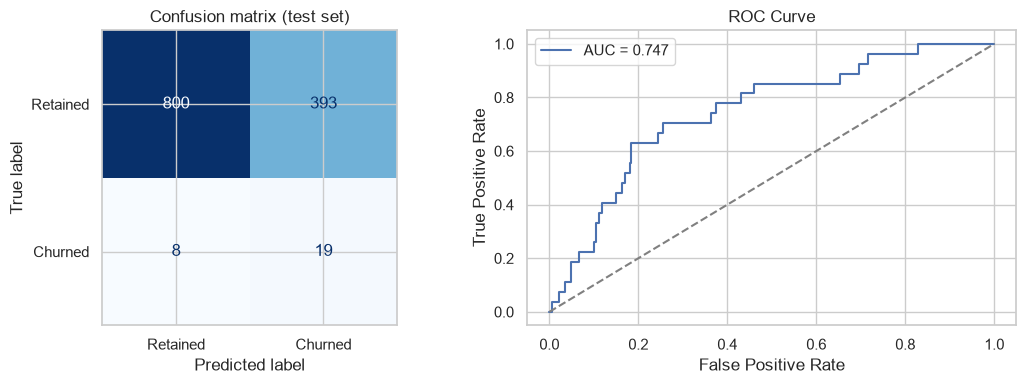

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Retained', 'Churned']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion matrix (test set)')

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_proba):.3f}', color='#4C72B0')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()


The positive class is small in this 90-day window. Scores and coefficients can be sensitive to the split and population definition. Independent observed histories are needed before using the model for customer decisions.

## Feature importance

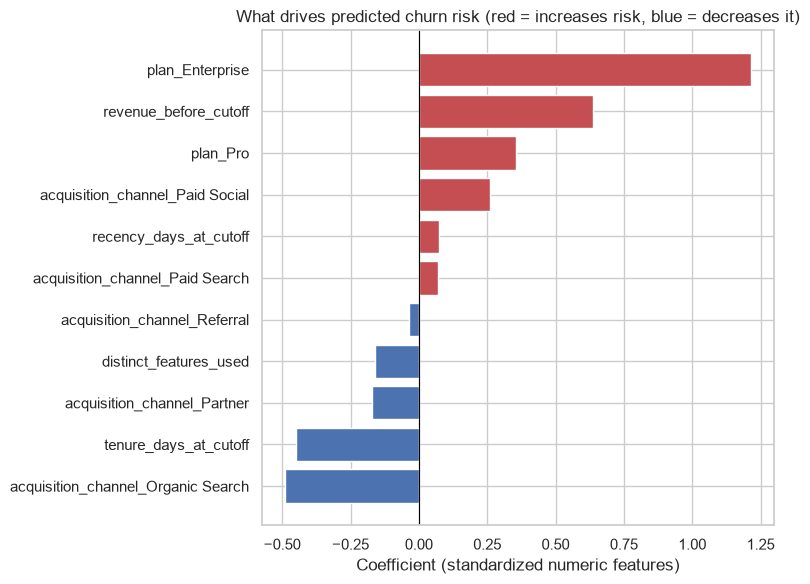

,feature,coefficient,odds_ratio
4,plan_Enterprise,1.213992,3.366899
3,revenue_before_cutoff,0.635568,1.888094
5,plan_Pro,0.353945,1.424677
8,acquisition_channel_Paid Social,0.260959,1.298175
1,recency_days_at_cutoff,0.073621,1.076398
7,acquisition_channel_Paid Search,0.070177,1.072698
10,acquisition_channel_Referral,-0.037450,0.963243
2,distinct_features_used,-0.159937,0.852198
9,acquisition_channel_Partner,-0.171298,0.842571
0,tenure_days_at_cutoff,-0.449413,0.638003


In [8]:
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0],
}).sort_values('coefficient')
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in coef_df['coefficient']]
ax.barh(coef_df['feature'], coef_df['coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient (standardized numeric features)')
ax.set_title('What drives predicted churn risk (red = increases risk, blue = decreases it)')
plt.tight_layout()
plt.show()

coef_df.sort_values('coefficient', ascending=False)


### Reading the coefficients

Numeric coefficients refer to standardized features; categorical coefficients compare a category with its reference level. Their signs and odds ratios describe associations within this fitted sample.

Plan, revenue, tenure, and activity are related by the generator. A plan coefficient therefore does not show that a plan causes churn or that a renewal strategy would change the outcome. Use these results to inspect the demonstration model, then evaluate any business hypothesis with independent data.